# **_INSTALL DEPENDENCIES_**

In [49]:
import os
import os.path as op
import requests
from urllib.request import urlretrieve
from IPython.display import Markdown, display


def create_folder(folder):
    if not op.exists(folder):
        os.mkdir(folder)
        print(f"Creating:\t\t {folder}")
    else:
        print(f"Already exist:\t\t {folder}")

def download_file(url, filename):
    if not op.exists(filename):
        print(f"Downloading:\t\t {url} --> {filename}")
        urlretrieve(url, filename)
    else:
        print(f"Already downloaded:\t {url} --> {filename}")


url = "https://raw.githubusercontent.com/KeremDUZENLI/python-keras-deep-learning/main/README.md"
FILES = "Files"
EX5DATA1_URL = "https://raw.githubusercontent.com/KeremDUZENLI/python-jupyter-machine-learning/refs/heads/main/notebooks/Files/ex5data1.mat"
EX5DATA1 = FILES + "/ex5data1.mat"

create_folder(FILES)
download_file(EX5DATA1_URL, EX5DATA1)

Already exist:		 Files
Already downloaded:	 https://raw.githubusercontent.com/KeremDUZENLI/python-jupyter-machine-learning/refs/heads/main/notebooks/Files/ex5data1.mat --> Files/ex5data1.mat


# Step 1: Import Libraries

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as optimize
from scipy.io import loadmat

# Step 2: Load Data

In [51]:
data = loadmat(EX5DATA1)
X = data['X']                 # (m,1)
y = data['y'].flatten()       # (m,)
Xval = data['Xval']
yval = data['yval'].flatten()

print("Training set size:", X.shape[0])

Training set size: 12


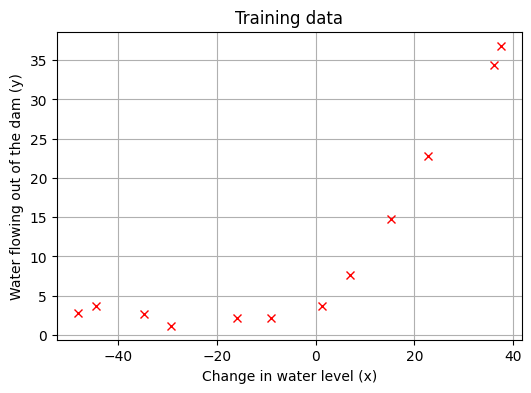

In [52]:
plt.figure(figsize=(6,4))
plt.plot(X, y, 'rx', markersize=6)
plt.xlabel('Change in water level (x)')
plt.ylabel('Water flowing out of the dam (y)')
plt.title('Training data')
plt.grid(True)
plt.show()

# Step 3: Test of Cost and Gradient

In [53]:
def linear_cost_function_reg(theta, X, y, lambda_):
    m = X.shape[0]
    theta = np.asarray(theta).reshape(-1)
    h = X.dot(theta)                     # (m,)
    residual = h - y                     # (m,)
    cost = 0.5 / m * np.sum(residual**2)

    # regularization excluding theta[0]
    reg = 0.5 * lambda_ / m * np.sum(theta[1:]**2)
    cost = cost + reg

    grad = (1.0 / m) * (X.T.dot(residual))   # (n,)
    reg_grad = (lambda_ / m) * theta
    reg_grad[0] = 0.0                         # no reg for theta[0]
    grad = grad + reg_grad

    return cost, grad

In [54]:
# prepare X with intercept
m = X.shape[0]
X_with_intercept = np.concatenate([np.ones((m,1)), X], axis=1)
theta_test = np.array([1.0, 1.0])
cost, grad = linear_cost_function_reg(theta_test, X_with_intercept, y, 1.0)

print(f"Cost at theta = [1,1]: {cost:.6f}")
print("Gradient at theta =\n", grad)
# expected (approx): Cost ~ 303.993192, Gradient ~ [-15.303016, 598.250744]

Cost at theta = [1,1]: 303.993192
Gradient at theta =
 [-15.30301567 598.25074417]


# Step 4: Train Linear Regression

In [55]:
def train_linear_regression(X, y, lambda_):
    n = X.shape[1]
    initial_theta = np.zeros(n)

    # local wrapper captures the X, y, lambda_ passed to this function
    def _func_to_minimize(t):
        J, grad = linear_cost_function_reg(t, X, y, lambda_)
        return J, grad

    res = optimize.minimize(
        _func_to_minimize,
        initial_theta,
        method='CG',
        jac=True,
        options={'maxiter':200, 'disp': False}
    )

    return res.x

Learned theta: [13.08790351  0.36777923]


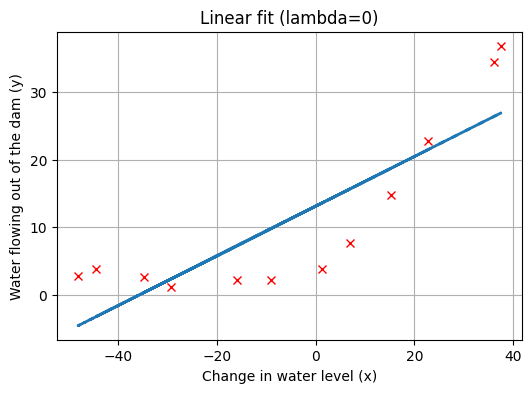

In [56]:
# quick train with lambda=0
lambda_ = 0.0
theta = train_linear_regression(X_with_intercept, y, lambda_)

print("Learned theta:", theta)

plt.figure(figsize=(6,4))
plt.plot(X, y, 'rx', markersize=6)
plt.plot(X, X_with_intercept.dot(theta), '--', linewidth=2)
plt.xlabel('Change in water level (x)')
plt.ylabel('Water flowing out of the dam (y)')
plt.title('Linear fit (lambda=0)')
plt.grid(True)

plt.show()

# Step 5: Run Learning Curve for Linear Model

In [57]:
def learning_curve(X, y, Xval, yval, lambda_):
    m = X.shape[0]
    err_train = np.zeros(m+1)
    err_val = np.zeros(m+1)

    for i in range(1, m+1):
        Xi = X[:i, :]
        yi = y[:i]
        theta_i = train_linear_regression(Xi, yi, lambda_)

        # compute train error on Xi with lambda=0
        J_train, _ = linear_cost_function_reg(theta_i, Xi, yi, 0.0)

        # compute val error on full Xval with lambda=0
        J_val, _ = linear_cost_function_reg(theta_i, Xval, yval, 0.0)
        err_train[i] = J_train
        err_val[i] = J_val

    return err_train, err_val

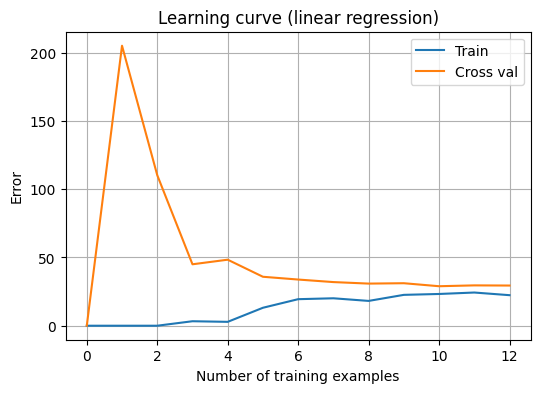

# Training Examples	Train Error	Cross Validation Error
	0		0.000000	0.000000
	1		0.000000	205.121096
	2		0.000000	110.300366
	3		3.286595	45.010232
	4		2.842678	48.368911
	5		13.154049	35.865141
	6		19.443963	33.829957
	7		20.098522	31.970987
	8		18.172859	30.862446
	9		22.609405	31.135998
	10		23.261462	28.936207
	11		24.317250	29.551432
	12		22.373906	29.433818


In [58]:
err_train, err_val = learning_curve(X_with_intercept, y, np.concatenate([np.ones((Xval.shape[0],1)), Xval], axis=1), yval, lambda_=0.0)

# plot
plt.figure(figsize=(6,4))
plt.plot(range(len(err_train)), err_train, label='Train')
plt.plot(range(len(err_val)), err_val, label='Cross val')
plt.xlabel('Number of training examples')
plt.ylabel('Error')
plt.title('Learning curve (linear regression)')
plt.legend()
plt.grid(True)
plt.show()

# print small table
print("# Training Examples\tTrain Error\tCross Validation Error")
for i in range(len(err_train)):
    print(f"\t{i}\t\t{err_train[i]:.6f}\t{err_val[i]:.6f}")

# Step 6: Polynomial Features and Normalization

In [59]:
def poly_features(X, p=8):
    """
    X : 1D array-like (m,) or 2D (m,1) -> returns (m, p) with columns x^1, x^2, ..., x^p
    """

    X = np.asarray(X).reshape(-1)
    m = X.shape[0]
    X_poly = np.zeros((m, p))

    #TODO: implement the polynomial feature mapping
    X = np.asarray(X).reshape(-1)

    for i in range(1, p +1):
        X_poly = np.column_stack((X_poly, X**i))
    
    

    return X_poly

In [67]:
def normalize_features(X, mu=None, sigma=None):
    """
    Normalize columns of X (zero mean, unit std). If mu/sigma provided, use them.
    Returns: X_norm, mu, sigma
    """

    X = np.asarray(X, dtype=float)
    
    #TODO: implement normalization of features
    if mu is None and sigma is None:
        mu = np.mean(X, axis=0)
        sigma = np.std(X, axis=0)

    sigma = np.where(sigma == 0, 1.0, sigma)
    X_norm = X.copy()
    X_norm = (X_norm - mu) / sigma

    return X_norm, mu, sigma

In [71]:
p = 8
Xpoly = poly_features(X[:, 0], p)
Xpoly_norm, mu, sigma = normalize_features(Xpoly)

print("Xpoly shape:", Xpoly.shape)
print("First normalized example:\n", Xpoly_norm[0], "mu: ", mu, "sigma: ", sigma)

Xpoly shape: (12, 16)
First normalized example:
 [ 0.          0.          0.          0.          0.          0.
  0.          0.         -0.3782437  -0.78866232  0.19032872 -0.7375913
  0.32025197 -0.6171516   0.35983501 -0.53109126] mu:  [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
 -5.08542635e+00  8.48904834e+02 -1.28290173e+04  1.28967789e+06
 -2.98314592e+07  2.29330301e+09 -6.84527284e+10  4.42233759e+12] sigma:  [1.00000000e+00 1.00000000e+00 1.00000000e+00 1.00000000e+00
 1.00000000e+00 1.00000000e+00 1.00000000e+00 1.00000000e+00
 2.86887308e+01 7.54346385e+02 4.61380464e+04 1.66104441e+06
 8.99399404e+07 3.68940106e+09 1.89508052e+11 8.31905350e+12]


# Step 7: Fit Polynomial Regression

In [62]:
p = 8
Xpoly = poly_features(X[:, 0], p)
Xpoly, mu, sigma = normalize_features(Xpoly)
Xpoly = np.concatenate([np.ones((Xpoly.shape[0],1)), Xpoly], axis=1)

Xval_poly = poly_features(Xval[:, 0], p)
Xval_poly, _, _ = normalize_features(Xval_poly, mu=mu, sigma=sigma)
Xval_poly = np.concatenate([np.ones((Xval_poly.shape[0],1)), Xval_poly], axis=1)

theta_poly = train_linear_regression(Xpoly, y, lambda_=0.0)

# plot original data and polynomial fit curve
x_plot = np.arange(min(X[:,0]) - 5, max(X[:,0]) + 5, 0.01)
x_poly_plot = poly_features(x_plot, p)
x_poly_plot, _, _ = normalize_features(x_poly_plot, mu=mu, sigma=sigma)
x_poly_plot = np.concatenate([np.ones((x_poly_plot.shape[0],1)), x_poly_plot], axis=1)
y_plot = x_poly_plot.dot(theta_poly)

print("First normalized training example features:\n", Xpoly[0])

First normalized training example features:
 [ 1.          0.          0.          0.          0.          0.
  0.          0.          0.         -0.3782437  -0.78866232  0.19032872
 -0.7375913   0.32025197 -0.6171516   0.35983501 -0.53109126]


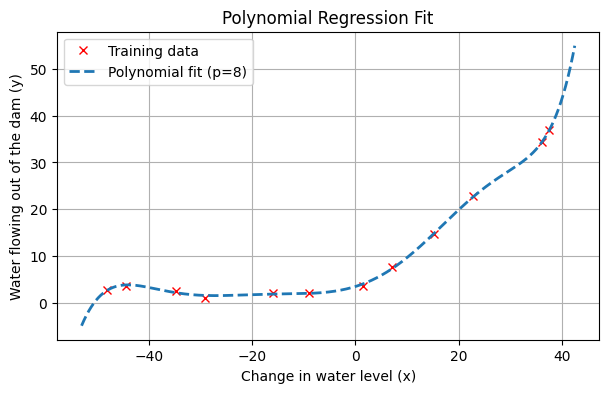

In [63]:
plt.figure(figsize=(7,4))
plt.plot(X, y, 'rx', markersize=6, label='Training data')
plt.plot(x_plot, y_plot, '--', linewidth=2, label=f'Polynomial fit (p={p})')
plt.xlabel('Change in water level (x)')
plt.ylabel('Water flowing out of the dam (y)')
plt.title('Polynomial Regression Fit')
plt.legend()
plt.grid(True)
plt.show()

# Step 8: Learning Curve for Polynomial Regression

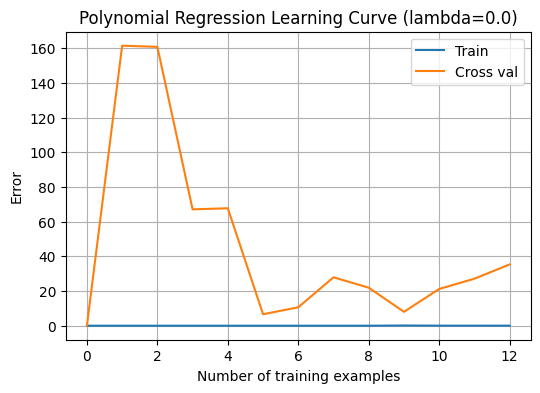

# Training Examples	Train Error	Cross Validation Error
	0		0.000000	0.000000
	1		0.000000	161.442168
	2		0.000000	160.792292
	3		0.000000	67.084922
	4		0.000000	67.726849
	5		0.000000	6.616987
	6		0.000003	10.629984
	7		0.000000	27.910059
	8		0.000115	21.926302
	9		0.120947	8.017827
	10		0.039276	21.193715
	11		0.038560	27.110961
	12		0.031891	35.350739


In [64]:
lambda_ = 0.0
err_train_poly, err_val_poly = learning_curve(Xpoly, y, Xval_poly, yval, lambda_)

plt.figure(figsize=(6,4))
plt.plot(range(len(err_train_poly)), err_train_poly, label='Train')
plt.plot(range(len(err_val_poly)), err_val_poly, label='Cross val')
plt.xlabel('Number of training examples')
plt.ylabel('Error')
plt.title(f'Polynomial Regression Learning Curve (lambda={lambda_})')
plt.legend()
plt.grid(True)
plt.show()

print("# Training Examples\tTrain Error\tCross Validation Error")
for i in range(len(err_train_poly)):
    print(f"\t{i}\t\t{err_train_poly[i]:.6f}\t{err_val_poly[i]:.6f}")

# Step 9: Validation Curve

In [65]:
def validation_curve(X, y, Xval, yval, lambda_vec=None):
    if lambda_vec is None:
        lambda_vec = np.array([0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])

    error_train = np.zeros(len(lambda_vec))
    error_val = np.zeros(len(lambda_vec))

    for i, l in enumerate(lambda_vec):
        theta_l = train_linear_regression(X, y, l)
        J_train, _ = linear_cost_function_reg(theta_l, X, y, 0.0)
        J_val, _ = linear_cost_function_reg(theta_l, Xval, yval, 0.0)
        error_train[i] = J_train
        error_val[i] = J_val

    return lambda_vec, error_train, error_val

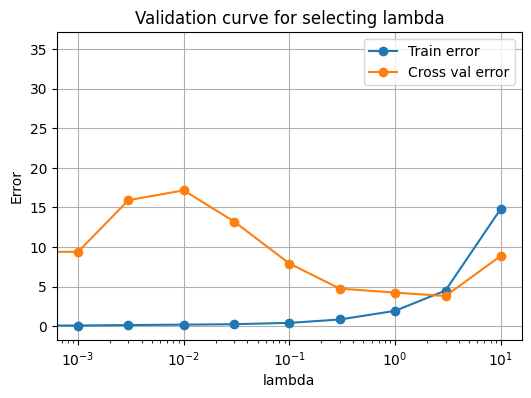

# lambda	Train Error	Cross Validation Error
0.000000	0.031891	35.350739
0.001000	0.108026	9.398818
0.003000	0.166695	15.921180
0.010000	0.218014	17.156286
0.030000	0.275129	13.218496
0.100000	0.438651	7.926929
0.300000	0.868177	4.760781
1.000000	1.958695	4.263359
3.000000	4.525105	3.832176
10.000000	14.825808	8.889725


In [66]:
lambda_vec, err_train_v, err_val_v = validation_curve(Xpoly, y, Xval_poly, yval)

plt.figure(figsize=(6,4))
plt.plot(lambda_vec, err_train_v, marker='o', label='Train error')
plt.plot(lambda_vec, err_val_v, marker='o', label='Cross val error')
plt.xscale('log')
plt.xlabel('lambda')
plt.ylabel('Error')
plt.title('Validation curve for selecting lambda')
plt.legend()
plt.grid(True)
plt.show()

print("# lambda\tTrain Error\tCross Validation Error")
for l, et, ev in zip(lambda_vec, err_train_v, err_val_v):
    print(f"{l:.6f}\t{et:.6f}\t{ev:.6f}")